# Additive models

[04_features.ipynb](04_features.ipynb) found that a random forest on its chosen RDKit descriptor set carries about half of the tier entropy, and its permutation importances say which descriptors it leans on — MolLogP first, then size, aromatic rings, PEOE_VSA6. They don't say *how*: whether solubility falls with logP in a straight line or bends, whether size saturates, where the thresholds sit. A forest can't be read; its prediction is a vote over hundreds of trees that each split on dozens of descriptors.

An explainable boosting machine (EBM; Lou, Caruana & Gehrke 2012; Nori et al. 2019, InterpretML) is a generalized additive model fitted by boosting: the log-odds of each tier is an intercept plus one *shape function* per descriptor — a step function of that descriptor alone — plus, optionally, a small number of pairwise terms. Every term can be drawn, and the model is nothing but the sum of its drawings, so this is the first model in the series that a person can read in full. Two questions:

1. **How many of the forest's bits survive when the model must be additive?** The forest can use any interaction between descriptors; the EBM only those it is explicitly allowed. The gap is the information that lives in interactions.
2. **What do the curves say?** The shape functions of the most important descriptors, read directly.

## Framework

- **Data and splits.** Unflagged votes with weight $1/n$ (flagged votes set aside), three split schemes that keep a skeleton on one side: random and cluster 10-fold cross-validation from `data/aqsoldb_splits.csv`, the five learned splits from `data/aqsoldb_splits_ls.csv`. As in [06_knn.ipynb](06_knn.ipynb).
- **Inputs.** Two sets, as in the features notebook: ESOL's four (MolLogP, MolWt, rotatable bonds, aromatic proportion — the readable baseline) and the RDKit set the features notebook carried downstream (one descriptor per correlation group; its size is printed with the data below).
- **Variants.** Main effects only, and with pairwise interaction terms; the number of pairs is chosen on the validation sides of the random splits from a declared grid.
- **Reference.** The random forest from the features notebook, on the same inputs and splits, so the additive model's cost is measured against a model free of the additivity constraint.
- **Scores.** From `scripts/aqsoldb_harness.py`: information $= H(T) - \text{log-loss}$ of the predicted tier distribution shrunk toward uniform by $\lambda$ chosen on the validation side (floor 0.005), plus the hard-tier accuracies. Two test populations: all test compounds, and those with 2+ unflagged votes, where the repeat-measurement benchmark is 0.963 bits and 76.5% in the same tier, held out. Cross-validation schemes show the mean over splits ± the standard error corrected for overlapping training sets; learning to split the mean ± standard deviation over seeds.
- **Description length**, declared before fitting: for an EBM, the number of main-effect terms, the number of bins across them (each bin holds one free number per tier), the number of interaction terms, and how many terms it takes to reach 90% of the summed term importance. One number common to every model family in this series: *the count of numbers needed to write the model down* — for an EBM, bins × tiers summed over terms; for a forest, leaves × tiers summed over trees.

In [1]:
import itertools
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from interpret.glassbox import ExplainableBoostingClassifier
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from sklearn.ensemble import RandomForestClassifier

RDLogger.DisableLog("rdApp.warning")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from aqsoldb_harness import METRICS, calibrate, corrected_se, formatted, score  # noqa: E402

votes = pd.read_csv(ROOT / "data" / "aqsoldb_tiers.csv")  # one row per vote: tier, weight, flag
values = votes[votes["weight"] > 0].reset_index(drop=True)  # flagged votes carry weight zero: set aside
TIERS = int(values["tier"].max()) + 1
splits = pd.read_csv(ROOT / "data" / "aqsoldb_splits.csv", index_col="InChIKey")  # one row per compound
learned = pd.read_csv(ROOT / "data" / "aqsoldb_splits_ls.csv", index_col="InChIKey").reindex(splits.index)
features = pd.read_csv(ROOT / "data" / "aqsoldb_features.csv", index_col="InChIKey").reindex(splits.index)
CV_SPLITS = [c for c in splits.columns if c.startswith("cv_") and c[3:].isdigit()]
CLUSTER_SPLITS = [c for c in splits.columns if c.startswith("cluster_") and c[8:].isdigit()]
LS_SPLITS = [c for c in learned.columns if c.startswith("ls_") and c[3:].isdigit()]
SCHEMES = {"random cross-validation": CV_SPLITS, "cluster cross-validation": CLUSTER_SPLITS, "learning to split": LS_SPLITS}
all_splits = splits.join(learned[LS_SPLITS])
assert LS_SPLITS, "run 05_learning_to_split.ipynb first"

compound = splits.index.get_indexer(values["InChIKey"])  # vote row -> compound
assert (compound >= 0).all(), "a vote's compound is missing from the splits"
y, w = values["tier"].to_numpy(), values["weight"].to_numpy()
n_compounds = len(splits)
repeated = np.bincount(compound, minlength=n_compounds) > 1  # compounds with 2+ unflagged votes
core = learned["ls_core"].to_numpy().astype(bool)

# ESOL's four inputs, computed as in 04_features.ipynb (aromatic proportion is not an RDKit descriptor).
mols = [Chem.MolFromSmiles(s) for s in values.groupby("InChIKey")["SMILES"].first().reindex(splits.index)]
assert all(mols), "a SMILES failed to parse"
esol = pd.DataFrame(
    {
        "MolLogP": [Descriptors.MolLogP(m) for m in mols],
        "MolWt": [Descriptors.MolWt(m) for m in mols],
        "NumRotatableBonds": [Descriptors.NumRotatableBonds(m) for m in mols],
        "AromaticProportion": [sum(a.GetIsAromatic() for a in m.GetAtoms()) / m.GetNumHeavyAtoms() for m in mols],
    },
    index=splits.index,
)
assert np.allclose(esol["MolLogP"], features["MolLogP"]), "MolLogP differs from the features hand-off"
DESCRIPTORS = f"RDKit, one per group ({features.shape[1]})"  # the set the features notebook handed down
INPUTS = {"ESOL (4)": esol, DESCRIPTORS: features}


def calibrate_on(proba: np.ndarray, on: np.ndarray) -> float:
    """λ chosen on every vote of the compounds in `on` (a mask over compounds)."""
    r = on[compound]
    return calibrate(y[r], proba[compound[r]], w[r])


def evaluate(proba: np.ndarray, on: np.ndarray, lam: float) -> dict:
    """Scores of a tier distribution per compound over every vote of the compounds in `on`."""
    r = on[compound]
    return score(y[r], proba[compound[r]], w[r], lam)


def sides(split: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    side = all_splits[split].to_numpy()
    train, validation, test = side == "train", side == "validation", side == "test"
    assert train.any() and validation.any() and test.any(), f"{split}: a side has no rows"
    return train, validation, test


def test_to_train(split_list: list[str]) -> float:
    return (all_splits[split_list[0]] == "test").sum() / (all_splits[split_list[0]] == "train").sum()


def validation_to_train(split_list: list[str]) -> float:
    return (all_splits[split_list[0]] == "validation").sum() / (all_splits[split_list[0]] == "train").sum()


print(f"{len(values)} votes, {n_compounds} compounds; {len(CV_SPLITS)} random, {len(CLUSTER_SPLITS)} cluster and {len(LS_SPLITS)} learned splits; "
      f"core of {core.sum()} compounds")

12013 votes, 9946 compounds; 10 random, 10 cluster and 5 learned splits; core of 912 compounds


## Choosing the number of interaction terms

InterpretML's EBM fits the main effects first, then (if asked) picks pairs by their gain on the residual and fits one two-dimensional step function per pair. The grid is declared here: 0, 5 and 20 pairs (capped at the number of pairs the inputs allow). Every setting is fitted on the train side of each random split, calibrated on its validation side and scored there; the setting with the best mean validation information per input set is carried to the test sides. The EBM's own settings (bins, bagging, learning rate, early stopping) are the package defaults, with the seed fixed.

In [2]:
INTERACTIONS = [0, 5, 20]
EBM_SETTINGS = dict(random_state=0, n_jobs=-1)  # InterpretML defaults otherwise
RF_SETTINGS = dict(n_estimators=500, n_jobs=-1, random_state=0)  # as in 04_features.ipynb


def interaction_grid(inputs: str) -> list[int]:
    n = INPUTS[inputs].shape[1]
    return sorted({min(k, n * (n - 1) // 2) for k in INTERACTIONS})


def fit_ebm(inputs: str, interactions: int, train: np.ndarray):
    """An EBM trained on every vote of the train compounds (each compound weighted once); tier distribution for every compound."""
    rows = train[compound]
    x = INPUTS[inputs]
    model = ExplainableBoostingClassifier(interactions=interactions, **EBM_SETTINGS).fit(x.iloc[compound[rows]], y[rows], sample_weight=w[rows])
    assert list(model.classes_) == list(range(TIERS)), "a tier is missing from the training rows"
    return model, model.predict_proba(x)


def fit_forest(inputs: str, train: np.ndarray):
    rows = train[compound]
    x = INPUTS[inputs].to_numpy()
    model = RandomForestClassifier(**RF_SETTINGS).fit(x[compound[rows]], y[rows], sample_weight=w[rows])
    assert list(model.classes_) == list(range(TIERS)), "a tier is missing from the training rows"
    return model, model.predict_proba(x)


started = time.time()
models, probas, rows = {}, {}, []
for inputs in INPUTS:
    for interactions, split in itertools.product(interaction_grid(inputs), CV_SPLITS):
        train, validation, test = sides(split)
        model, proba = fit_ebm(inputs, interactions, train)
        models[inputs, interactions, split], probas[inputs, interactions, split] = model, proba
        lam = calibrate_on(proba, validation)
        rows.append({"inputs": inputs, "interactions": interactions, "split": split, "λ": lam, **evaluate(proba, validation, lam)})
print(f"{len(rows)} fits in {(time.time() - started) / 60:.0f} min")

by_setting = pd.DataFrame(rows).groupby(["inputs", "interactions"], sort=False)
sweep = by_setting["information (bits)"].agg(["mean", "var"])
sweep["SE"] = np.sqrt((1 / len(CV_SPLITS) + validation_to_train(CV_SPLITS)) * sweep.pop("var"))
sweep["accuracy: same tier (%)"] = by_setting["accuracy: same tier (%)"].mean()
sweep["λ (median)"] = by_setting["λ"].median()
sweep = sweep.rename(columns={"mean": "validation information (bits)"})
BEST = {inputs: int(sweep.loc[inputs, "validation information (bits)"].idxmax()) for inputs in INPUTS}
print("chosen:", BEST)
sweep.round(3)

/Users/kthrossell/working/mini-model-exploration/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:1249: UserWarning: For multiclass we cannot currently visualize pairs and they will be stripped from the global explanations. Set interactions=0 to generate a fully interpretable glassbox model.
  warn(


/Users/kthrossell/working/mini-model-exploration/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


60 fits in 50 min
chosen: {'ESOL (4)': 5, 'RDKit, one per group (152)': 20}


validation information (bits)     SE  \
inputs                     interactions                                         
ESOL (4)                   0                                     0.726  0.012   
                           5                                     0.810  0.010   
                           6                                     0.809  0.011   
RDKit, one per group (152) 0                                     0.936  0.015   
                           5                                     0.941  0.015   
                           20                                    0.949  0.014   

                                         accuracy: same tier (%)  λ (median)  
inputs                     interactions                                       
ESOL (4)                   0                              65.204       0.008  
                           5                              67.064       0.005  
                           6                              67.056       0.005  
RDKit, one per group (152) 0                              71.687       0.020  
                           5                              72.001       0.020  
                           20                             72.244       0.020

## Against the random forest, on three kinds of split

For each input set: the EBM with main effects only, the EBM with the chosen number of pairs (when that is not zero), and the random forest. Each is trained on a split's train side, calibrated on its validation side and scored on its test side, on the random, cluster and learned splits. The random-split EBMs are the fits above; the others are fitted here.

In [3]:
SUBSETS = {"all test compounds": np.ones(n_compounds, bool), "test compounds with 2+ unflagged votes": repeated}
PREDICTORS = {}  # name -> (inputs, interactions or None for the forest)
for inputs in INPUTS:
    PREDICTORS[f"EBM, main effects, {inputs}"] = (inputs, 0)
    if BEST[inputs]:
        PREDICTORS[f"EBM, {BEST[inputs]} pairs, {inputs}"] = (inputs, BEST[inputs])
    PREDICTORS[f"random forest, {inputs}"] = (inputs, None)

started = time.time()
rows = []
for name, (inputs, interactions) in PREDICTORS.items():
    for scheme, split_list in SCHEMES.items():
        for split in split_list:
            train, validation, test = sides(split)
            if interactions is None:
                models[inputs, "forest", split], proba = fit_forest(inputs, train)
            elif (inputs, interactions, split) in probas:
                proba = probas[inputs, interactions, split]
            else:
                models[inputs, interactions, split], proba = fit_ebm(inputs, interactions, train)
            lam = calibrate_on(proba, validation)
            for subset, mask in SUBSETS.items():
                rows.append({"predictor": name, "scheme": scheme, "split": split, "subset": subset, "λ": lam, **evaluate(proba, test & mask, lam)})
held_out = pd.DataFrame(rows)
print(f"{(time.time() - started) / 60:.0f} min")

tables, means = {}, {}
for name in PREDICTORS:
    blocks = {}
    for scheme, split_list in SCHEMES.items():
        d = held_out[(held_out["predictor"] == name) & (held_out["scheme"] == scheme)]
        by = d.groupby("subset", sort=False)[list(METRICS)]
        if scheme == "learning to split":
            spread = by.std()
            blocks[f"{scheme} (mean ± SD)"] = formatted(by.mean()) + " ± " + formatted(spread)
        else:
            spread = by.apply(lambda g: g.apply(corrected_se, n_splits=len(split_list), test_to_train=test_to_train(split_list)))
            blocks[f"{scheme} (mean ± SE)"] = formatted(by.mean()) + " ± " + formatted(spread)
        for subset in SUBSETS:
            means[name, scheme, subset] = (by.mean().loc[subset, "information (bits)"], spread.loc[subset, "information (bits)"])
    tables[name] = pd.concat(blocks, names=["split", "subset"])
pd.concat(tables, names=["predictor"])[["information (bits)", "accuracy: same tier (%)", "1 tier off (%)", "2+ tiers off (%)"]]

/Users/kthrossell/working/mini-model-exploration/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:1249: UserWarning: For multiclass we cannot currently visualize pairs and they will be stripped from the global explanations. Set interactions=0 to generate a fully interpretable glassbox model.
  warn(


/Users/kthrossell/working/mini-model-exploration/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


/Users/kthrossell/working/mini-model-exploration/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:1249: UserWarning: For multiclass we cannot currently visualize pairs and they will be stripped from the global explanations. Set interactions=0 to generate a fully interpretable glassbox model.
  warn(


29 min


information (bits)  \
predictor                                     split                                subset                                                      
EBM, main effects, ESOL (4)                   random cross-validation (mean ± SE)  all test compounds                          0.726 ± 0.013   
                                                                                   test compounds with 2+ unflagged votes      0.714 ± 0.041   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.714 ± 0.032   
                                                                                   test compounds with 2+ unflagged votes      0.708 ± 0.048   
                                              learning to split (mean ± SD)        all test compounds                         -0.877 ± 0.064   
                                                                                   test compounds with 2+ unflagged votes     -0.641 ± 0.163   
EBM, 5 pairs, ESOL (4)                        random cross-validation (mean ± SE)  all test compounds                          0.808 ± 0.009   
                                                                                   test compounds with 2+ unflagged votes      0.799 ± 0.051   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.784 ± 0.030   
                                                                                   test compounds with 2+ unflagged votes      0.792 ± 0.047   
                                              learning to split (mean ± SD)        all test compounds                         -1.046 ± 0.118   
                                                                                   test compounds with 2+ unflagged votes     -0.810 ± 0.206   
random forest, ESOL (4)                       random cross-validation (mean ± SE)  all test compounds                          0.769 ± 0.011   
                                                                                   test compounds with 2+ unflagged votes      0.753 ± 0.061   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.725 ± 0.032   
                                                                                   test compounds with 2+ unflagged votes      0.734 ± 0.045   
                                              learning to split (mean ± SD)        all test compounds                         -1.258 ± 0.091   
                                                                                   test compounds with 2+ unflagged votes     -0.975 ± 0.104   
EBM, main effects, RDKit, one per group (152) random cross-validation (mean ± SE)  all test compounds                          0.936 ± 0.012   
                                                                                   test compounds with 2+ unflagged votes      0.917 ± 0.054   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.895 ± 0.030   
                                                                                   test compounds with 2+ unflagged votes      0.884 ± 0.045   
                                              learning to split (mean ± SD)        all test compounds                         -1.448 ± 0.171   
                                                                                   test compounds with 2+ unflagged votes     -0.884 ± 0.097   
EBM, 20 pairs, RDKit, one per group (152)     random cross-validation (mean ± SE)  all test compounds                          0.950 ± 0.013   
                                                                                   test compounds with 2+ unflagged votes      0.928 ± 0.057   
                                              cluster cross-validation (mean ± SE) all tes

**Reading the table.** On ESOL's four descriptors the additive model is not the weaker one. Main effects alone trail the forest by 0.04 bits on random splits (0.726 against 0.769), and five pairwise terms turn that into a lead of 0.04 bits (0.808) that widens to 0.06 on cluster splits (0.784 against 0.725). With four inputs there are only six pairs, so the five-pair EBM already sees nearly every interaction the forest can use, and it uses them with less variance. On the 152 descriptors the order reverses: main effects carry 0.936 bits against the forest's 1.009 on random splits and 0.895 against 0.941 on cluster splits, and twenty pairs recover only 0.014 of the 0.073-bit gap. The information that lives in interactions among the 152 descriptors, beyond what twenty pairs catch, is therefore about 0.06 bits — six percent of what the forest carries — and the additive constraint costs about as much on unfamiliar chemistry (0.046 bits on cluster splits) as on familiar. Hard-tier accuracy says the same more gently: 72.2% against 73.7% in the same tier, 3.0% against 2.6% two or more tiers off.

On the benchmark population the twenty-pair EBM carries 0.928 ± 0.057 bits, within one standard error of the 0.963-bit repeat benchmark; the forest's 0.991 sits on the other side of it.

The learned splits are the exception. Every model is negative there — the splits were chosen to be the hardest — but the EBMs are far more negative than the forest (−1.448 and −1.619 against −0.609 on all compounds) while their same-tier accuracy is the same (23.3% and 23.4% against 23.9%). Equal accuracy with less information means the loss is confidence, not ranking. The likely mechanism: outside the range it was trained on, each of an EBM's step functions sits at its last value and the 152 terms keep adding, so a compound in unfamiliar chemistry gets a sharp distribution on a wrong tier where the forest's vote spreads out; more pairs make it sharper still. On the hardest held-out chemistry the additive model is as right as the forest and more sure when it is wrong.

## Description length

The declared counts, averaged over the ten random-split fits of each model. "Terms for 90% of importance" sorts the terms by InterpretML's term importance (the mean absolute contribution of the term to the log-odds over the training rows) and counts how many it takes to reach 90% of the total: a model with 130 shape functions of which a dozen do the work is shorter to read than the count of terms suggests. The forest's length is its leaves; it is reported in the same units as the EBM so the front across model families can be drawn, not because anyone will read 500 trees.

The counts are written to `data/aqsoldb_front_additive.csv` with the held-out information, one row per model, scheme and test population, for the front notebook.

In [4]:
def ebm_length(model) -> dict:
    mains = [i for i, t in enumerate(model.term_features_) if len(t) == 1]
    pairs = [i for i, t in enumerate(model.term_features_) if len(t) == 2]
    importance = model.term_importances()
    order = np.argsort(importance)[::-1]
    effective = int(np.searchsorted(np.cumsum(importance[order]) / importance.sum(), 0.9) + 1)
    return {
        "main-effect terms": len(mains),
        "bins across main effects": sum(model.term_scores_[i].shape[0] - 2 for i in mains),  # less the missing and unseen bins
        "interaction terms": len(pairs),
        "terms for 90% of importance": effective,
        "numbers to write it down": sum(model.term_scores_[i].size for i in range(len(model.term_features_))),
    }


def forest_length(model) -> dict:
    leaves = sum(t.tree_.n_leaves for t in model.estimators_)
    return {"main-effect terms": np.nan, "bins across main effects": np.nan, "interaction terms": np.nan, "terms for 90% of importance": np.nan,
            "numbers to write it down": leaves * TIERS}


lengths = {}
for name, (inputs, interactions) in PREDICTORS.items():
    per_split = [forest_length(models[inputs, "forest", s]) if interactions is None else ebm_length(models[inputs, interactions, s]) for s in CV_SPLITS]
    lengths[name] = pd.DataFrame(per_split).mean()
lengths = pd.DataFrame(lengths).T

front = pd.DataFrame(
    [{"model": name, "family": "random forest" if interactions is None else "EBM", "inputs": inputs, "scheme": scheme, "subset": subset,
      "information (bits)": means[name, scheme, subset][0], "spread": means[name, scheme, subset][1],
      "numbers to write it down": lengths.loc[name, "numbers to write it down"], "readable": interactions is not None}
     for name, (inputs, interactions) in PREDICTORS.items() for scheme in SCHEMES for subset in SUBSETS]
)
front.to_csv(ROOT / "data" / "aqsoldb_front_additive.csv", index=False)
lengths.round(0).astype("Int64")

,main-effect terms,bins across main effects,interaction terms,terms for 90% of importance,numbers to write it down
"EBM, main effects, ESOL (4)",4,2350,0,3,9434
"EBM, 5 pairs, ESOL (4)",4,2350,5,7,72850
"random forest, ESOL (4)",<NA>,<NA>,<NA>,<NA>,4291988
"EBM, main effects, RDKit, one per group (152)",152,60090,0,82,241575
"EBM, 20 pairs, RDKit, one per group (152)",152,60090,20,77,512961
"random forest, RDKit, one per group (152)",<NA>,<NA>,<NA>,<NA>,3129277


## The shape functions

The six most important main effects of the chosen model on the RDKit descriptors, by mean term importance over the ten random-split fits. Each panel draws, for each tier, the term's contribution to that tier's log-odds against the descriptor's value, as the median over the ten fits with the interquartile range shaded; where the band is narrow the curve is a property of the data, not of one fit. The x-range runs from the 1st to the 99th percentile of the descriptor over all compounds. Because the four curves of a term sum to about zero at every value (the EBM centres them), reading one tier's curve against the others is reading the model's whole opinion of that descriptor.

The full ranking of main effects by mean importance is written to `data/aqsoldb_ebm_importance.csv`; the symbolic-regression notebook uses it to pick a small input set.

,mean term importance over 10 fits
MolLogP,0.580
VSA_EState2,0.214
BCUT2D_MWLOW,0.171
SlogP_VSA2,0.168
MinPartialCharge,0.155
ExactMolWt,0.135
PEOE_VSA6,0.127
Kappa1,0.122
MinEStateIndex,0.121
HallKierAlpha,0.119


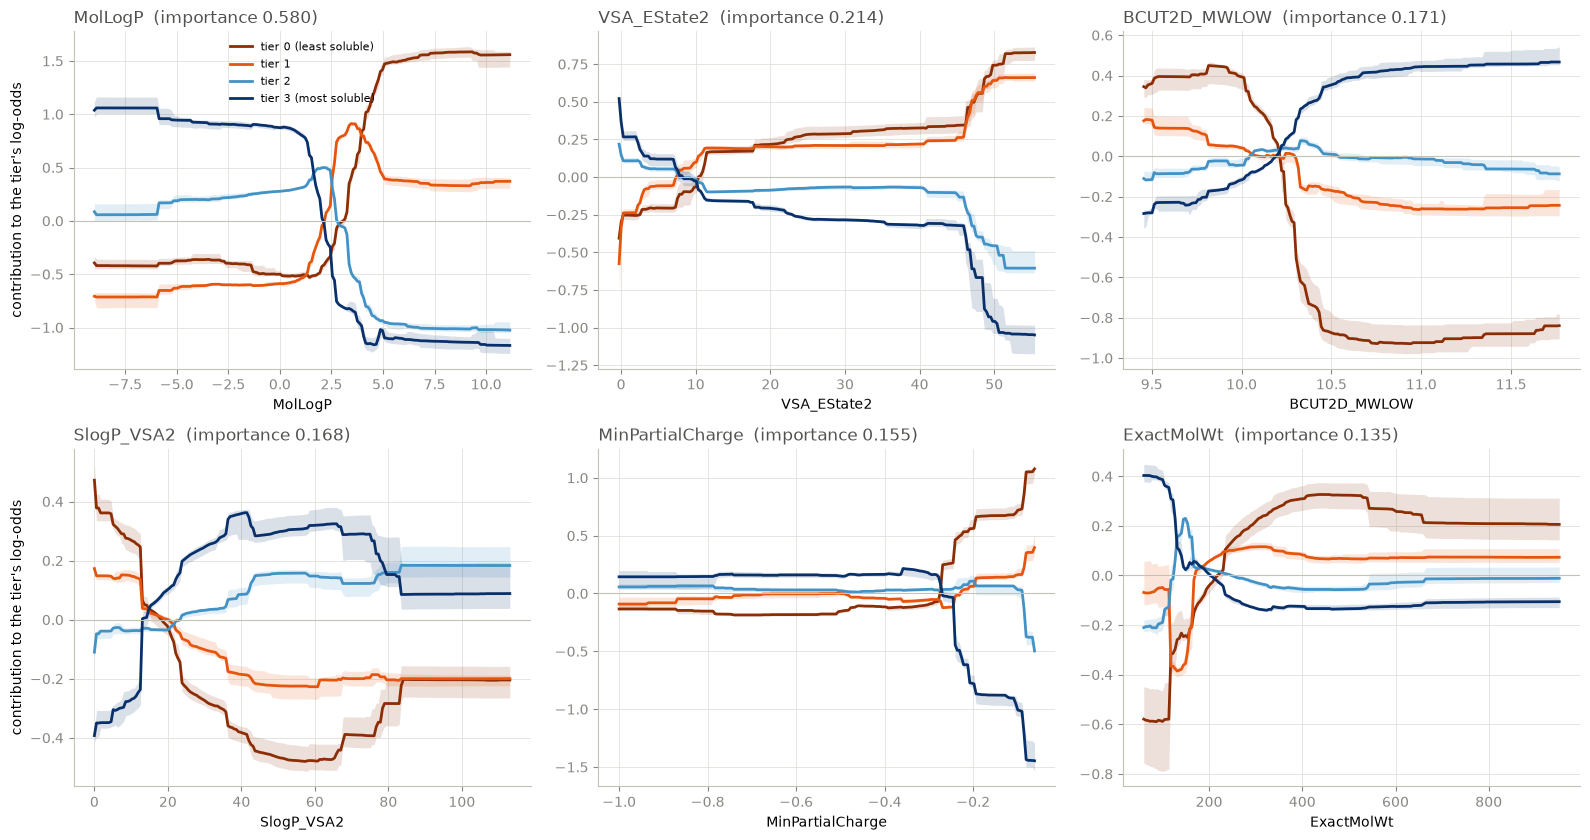

In [5]:
INK, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"  # as in 01_prep_and_analysis.ipynb
TIER_COLORS = ["#8c2d04", "#e6550d", "#4292c6", "#08306b"]  # least to most soluble
TIER_LABELS = ["tier 0 (least soluble)", "tier 1", "tier 2", "tier 3 (most soluble)"]
CHOSEN = DESCRIPTORS
N_SHAPES, GRID_POINTS = 6, 200


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)


chosen_models = [models[CHOSEN, BEST[CHOSEN], s] for s in CV_SPLITS]
x_all = INPUTS[CHOSEN]
main_names = [n for n, t in zip(chosen_models[0].term_names_, chosen_models[0].term_features_) if len(t) == 1]
importance = pd.DataFrame(
    [dict(zip(m.term_names_, m.term_importances())) for m in chosen_models]
).mean().reindex(main_names).sort_values(ascending=False)
top = list(importance.index[:N_SHAPES])


def shape(model, name: str, grid: np.ndarray) -> np.ndarray:
    """The term's contribution to each tier's log-odds along `grid` (other descriptors at their median; they don't enter the term)."""
    frame = pd.DataFrame(np.tile(x_all.median().to_numpy(), (len(grid), 1)), columns=x_all.columns)
    frame[name] = grid
    return np.asarray(model.eval_terms(frame))[:, model.term_names_.index(name), :]


fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, name in zip(axes.flat, top):
    lo, hi = x_all[name].quantile([0.01, 0.99])
    grid = np.linspace(lo, hi, GRID_POINTS) if hi > lo else np.array([lo])
    curves = np.stack([shape(m, name, grid) for m in chosen_models])  # fits × grid × tiers
    q25, q50, q75 = np.percentile(curves, [25, 50, 75], axis=0)
    for t in range(TIERS):
        ax.fill_between(grid, q25[:, t], q75[:, t], color=TIER_COLORS[t], alpha=0.15, lw=0)
        ax.plot(grid, q50[:, t], color=TIER_COLORS[t], lw=2, label=TIER_LABELS[t])
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(f"{name}  (importance {importance[name]:.3f})", loc="left", color=INK)
    ax.set_xlabel(name)
    style(ax)
for ax in axes[:, 0]:
    ax.set_ylabel("contribution to the tier's log-odds")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
importance.rename("mean term importance over 10 fits").to_csv(ROOT / "data" / "aqsoldb_ebm_importance.csv")  # hand-off: ranked main effects
importance.head(15).round(3).to_frame("mean term importance over 10 fits")

### Which pairs does it pick?

For the chosen model on the RDKit descriptors: the pairs selected in the ten random-split fits, how many fits selected each, and their mean importance. A pair that every fit picks is a feature of the data; one picked once is a feature of the fold.

In [6]:
if BEST[CHOSEN]:
    pair_rows = []
    for m in chosen_models:
        for name, t, imp in zip(m.term_names_, m.term_features_, m.term_importances()):
            if len(t) == 2:
                pair_rows.append({"pair": name, "importance": imp})
    pairs = pd.DataFrame(pair_rows).groupby("pair")["importance"].agg(fits="size", mean_importance="mean").sort_values(["fits", "mean_importance"], ascending=False)
    print(f"{len(pairs)} distinct pairs over {len(chosen_models)} fits of {BEST[CHOSEN]} pairs each; "
          f"{(pairs['fits'] == len(chosen_models)).sum()} chosen in every fit")
    display(pairs.head(20).round(3))
else:
    print("main effects only were chosen on the 130 descriptors: no pairs to show")

110 distinct pairs over 10 fits of 20 pairs each; 0 chosen in every fit


,fits,mean_importance
pair,,
MolLogP & TPSA,7,0.094
MolLogP & Kappa1,7,0.081
ExactMolWt & VSA_EState5,5,0.047
MinEStateIndex & Kappa1,5,0.037
EState_VSA5 & BCUT2D_MRLOW,5,0.031
ExactMolWt & fr_COO,4,0.122
MolLogP & BertzCT,4,0.049
MolLogP & BCUT2D_LOGPHI,4,0.048
VSA_EState5 & FpDensityMorgan1,4,0.045


## Reading

1. **How many of the forest's bits survive when the model must be additive?** Nearly all of them. On the 152 descriptors the main-effects EBM carries 0.936 bits on random splits and 0.895 on cluster splits against the forest's 1.009 and 0.941; twenty pairwise terms add 0.014. The additivity constraint costs about 0.07 of the forest's 1.009 bits on familiar chemistry and 0.05 of its 0.941 on unfamiliar, and it buys a model written in 240 thousand numbers instead of 3.1 million — thirteen times shorter, every term of it drawable. On ESOL's four descriptors the constraint costs nothing: with five pairs the EBM carries 0.808 bits to the forest's 0.769 at one sixtieth of the length. The one place the additive model is clearly worse is the learned splits, where it is as accurate as the forest and much more confident in its errors.

2. **What do the curves say?** MolLogP's shape function has 2.7 times the importance of the next term, and it is not a line. Each tier's contribution is flat at the low end (below logP ≈ 0 for the most-soluble tier, below ≈ 2.5 for the least), flat again above ≈ 5, and all the movement is in between — a sigmoid, with the four tiers peaking in order: most soluble on the low plateau, tier 2 near logP 2.5, tier 1 near 3.5, least soluble on the high plateau. The model reads logP as an ordinal ladder with saturation at both ends; beyond logP 5 or below 0 it has nothing more to say. Size saturates early: the most-soluble tier's ExactMolWt contribution falls from +0.4 below 120 Da to its floor by about 250 Da and is flat thereafter, and the least-soluble tier's peaks near 400 Da and drifts down beyond 500. MinPartialCharge is flat over the whole range below −0.25 and acts only in its tail: a compound with no atom carrying a substantial negative partial charge — in practice, no oxygen or nitrogen — gets +1 to the least-soluble log-odds and −1.4 to the most-soluble. VSA_EState2 and BCUT2D_MWLOW act as near-steps (at about 45 and 10.3) rather than slopes; SlogP_VSA2 is the one non-monotone curve of the six, with the most-soluble tier favoured between 20 and 80 and the least-soluble disfavoured there. Where the interquartile bands are narrow — MolLogP everywhere, the others over most of their range — these are properties of the data, not of a fit.

3. **Pairs are a property of the fold, not of the data.** Ten fits of twenty pairs chose 110 distinct pairs and none in every fit; the most repeated, MolLogP with TPSA and MolLogP with Kappa1, appeared in seven fits each. That matches their 0.014 bits: the interactions the EBM can find are small and unstable, and the 0.06 bits the forest still holds over the twenty-pair model are either spread over many weak interactions or come from the forest's other freedom, adapting locally within a descriptor rather than across descriptors.

4. **Length.** Eighty-two of the 152 shape functions are needed for 90% of the importance, so the model does not collapse to a dozen descriptors, and the bins-times-tiers count (241,575) overstates what a reader must take in: the six curves above carry most of the story, and each is a few plateaus and a transition. The front notebook plots this model at its full declared length; the honest reading is that the EBM is the first point on the front that a person can read end to end.